# Знакомство с Intel Image Classification

В датасете шесть классов: **buildings** (здания), **forest** (лес), **glacier** (ледник), **mountain** (горы), **sea** (море), **street** (улица).

Посмотрим, сколько снимков в каждом классе и как они выглядят. Затем превратим фотографию в тензор и соберём первый батч для будущей CNN. Для этого этапа достаточно CPU.


In [1]:
from pathlib import Path
from collections import Counter
import random

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

# Запуск из корня проекта или из notebooks/.
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

train_dir = project_root / "data/seg_train/seg_train"
test_dir = project_root / "data/seg_test/seg_test"


In [2]:
# ImageFolder берёт названия классов из папок и нумерует их по алфавиту
# Фотографии читаются по одной при обращении к датасету
train_dataset = datasets.ImageFolder(train_dir)
test_dataset = datasets.ImageFolder(test_dir)
classes = train_dataset.classes

print("Классы:", ", ".join(classes))
print(f"Обучающая выборка: {len(train_dataset):,} изображений")
print(f"Тестовая выборка:   {len(test_dataset):,} изображений")


Классы: buildings, forest, glacier, mountain, sea, street
Обучающая выборка: 14,034 изображений
Тестовая выборка:   3,000 изображений


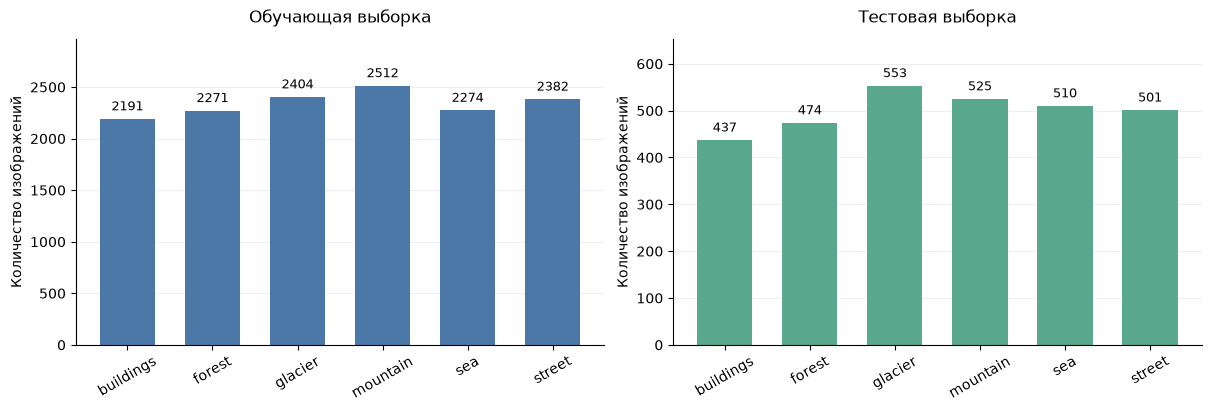

In [ ]:
# Сравним количество фотографий в каждом классе
train_counts = Counter(train_dataset.targets)
test_counts = Counter(test_dataset.targets)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, counts, title, color in zip(
    axes,
    [train_counts, test_counts],
    ["Обучающая выборка", "Тестовая выборка"],
    ["#4C78A8", "#59A88E"],
):
    values = [counts[i] for i in range(len(classes))]
    bars = ax.bar(classes, values, color=color, width=0.65)
    ax.bar_label(bars, padding=4, fontsize=9)
    ax.set_title(title, pad=12)
    ax.set_ylabel("Количество изображений")
    ax.set_ylim(0, max(values) * 1.18)
    ax.tick_params(axis="x", labelrotation=30)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

plt.show()


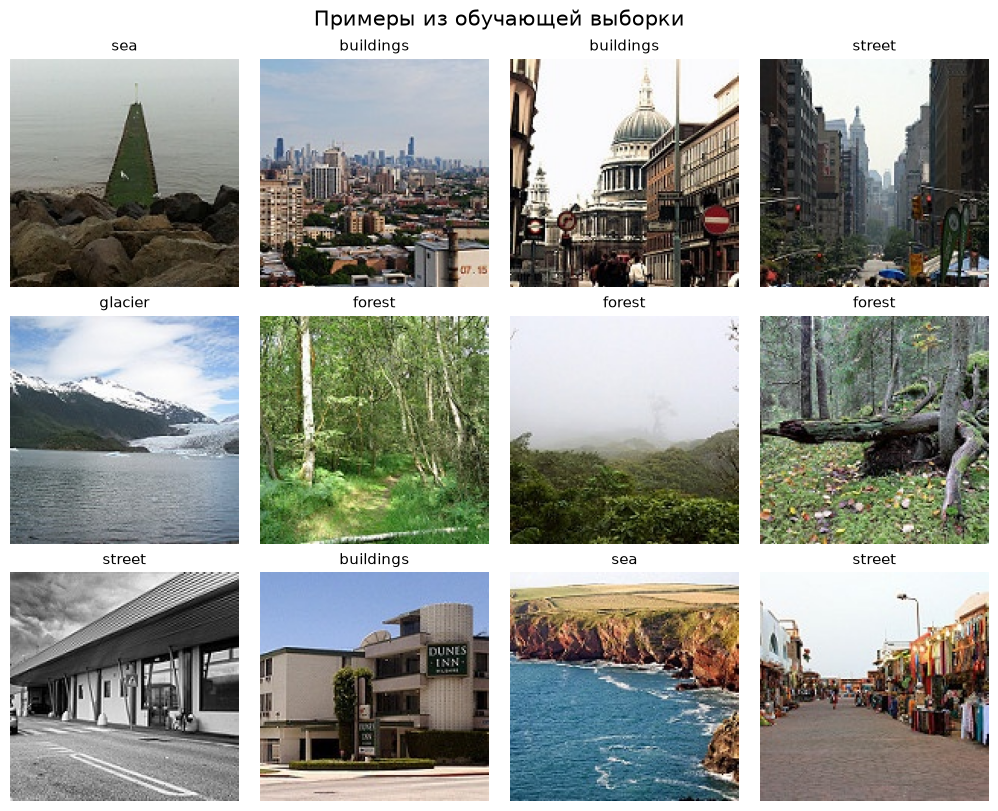

In [4]:
# Случайные фотографии без изменения исходных размеров.
indices = random.Random(SEED).sample(range(len(train_dataset)), 12)
fig, axes = plt.subplots(3, 4, figsize=(10, 8), layout="constrained")
fig.suptitle("Примеры из обучающей выборки", fontsize=15)

for ax, index in zip(axes.flat, indices):
    image, label = train_dataset[index]
    ax.imshow(image)
    ax.set_title(classes[label], fontsize=11)
    ax.axis("off")

plt.show()


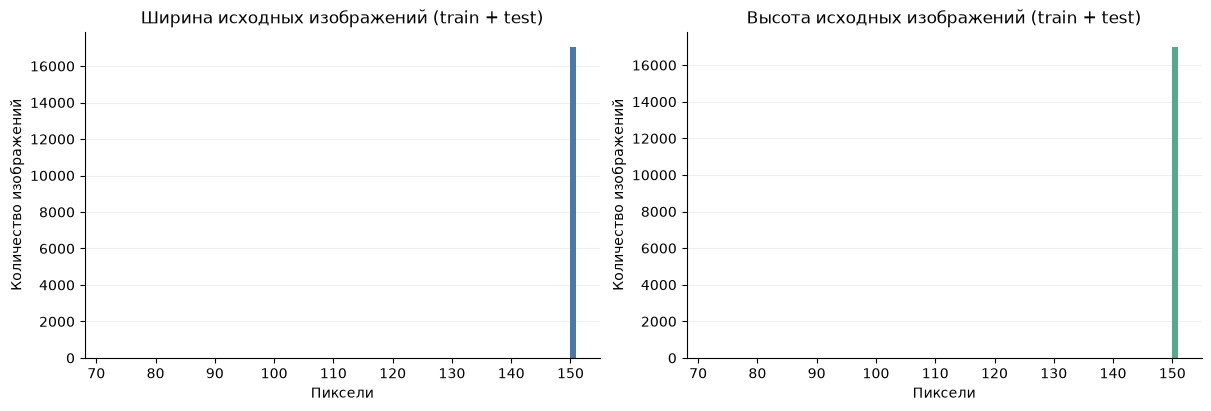

Ширина: 150–150 пикселей
Высота: 72–150 пикселей
Размер 150×150: 16,979 из 17,034


In [5]:
# Исходные размеры всех снимков train/test: читаем только заголовки файлов.
from PIL import Image

widths, heights = [], []
for dataset in (train_dataset, test_dataset):
    for image_path, _ in dataset.samples:
        with Image.open(image_path) as image:
            width, height = image.size
        widths.append(width)
        heights.append(height)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
bins = range(min(widths + heights), max(widths + heights) + 2)
for ax, values, title, color in zip(
    axes, [widths, heights], ["Ширина", "Высота"], ["#4C78A8", "#59A88E"],
):
    ax.hist(values, bins=bins, color=color)
    ax.set_title(f"{title} исходных изображений (train + test)")
    ax.set_xlabel("Пиксели")
    ax.set_ylabel("Количество изображений")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
plt.show()

print(f"Ширина: {min(widths)}–{max(widths)} пикселей")
print(f"Высота: {min(heights)}–{max(heights)} пикселей")
print(f"Размер 150×150: {sum(w == 150 and h == 150 for w, h in zip(widths, heights)):,} из {len(widths):,}")


In [ ]:
# ToTensor переводит RGB-пиксели из 0-255 в float32 со значениями 0-1
image, label = train_dataset[indices[0]]
tensor = transforms.ToTensor()(image)

print("Класс:", classes[label])
print("Исходный размер (ширина, высота):", image.size)
print("Форма тензора (каналы, высота, ширина):", tuple(tensor.shape))
print("Тип данных:", tensor.dtype)
print(f"Диапазон значений: {tensor.min().item():.3f}–{tensor.max().item():.3f}")


Класс: sea
Исходный размер (ширина, высота): (150, 150)
Форма тензора (каналы, высота, ширина): (3, 150, 150)
Тип данных: torch.float32
Диапазон значений: 0.000–0.961


In [7]:
# Для батча нужны тензоры одинакового размера: приведём снимки к 150×150
transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
])
train_tensors = datasets.ImageFolder(train_dir, transform=transform) # создаем объект датасета

# DataLoader читает и объединяет изображения батчами
train_loader = DataLoader(
    train_tensors,
    batch_size=16,
    shuffle=True,       # изображения перемешиваются
    generator=torch.Generator().manual_seed(SEED),
)
images, labels = next(iter(train_loader)) # достаем 1 батч на проверку

print("Форма батча:", tuple(images.shape))
print("Оси: 16 изображений, 3 RGB-канала, 150 пикселей в высоту и ширину")
print("Форма меток:", tuple(labels.shape))
print("Метки классов:", labels.tolist())  # Один числовой индекс на фотографию


Форма батча: (16, 3, 150, 150)
Оси: 16 изображений, 3 RGB-канала, 150 пикселей в высоту и ширину
Форма меток: (16,)
Метки классов: [4, 2, 2, 4, 4, 1, 2, 4, 4, 5, 3, 5, 3, 5, 0, 4]


## Вывод

- В train 14 034 снимка, в test - 3 000. Число примеров по классам близко, сильного дисбаланса нет.
- Ледники и горы могут быть похожи; здания встречаются и на снимках улиц
- Тензор одного снимка имеет оси `(C, H, W)`, батч — `(N, C, H, W)`. `Resize` изменяет размер загружаемых изображений, не меняя оригиналы на диске.

Большинство исходных снимков имеют размер 150×150, но высота некоторых меньше. Поэтому для батча нужен единый размер. В EDA оставляем 150×150 для демонстрации, а для CNN выбираем `Resize((128, 128))`: меньший размер снижает затраты вычислений на CPU.

Дальше выделим валидационную выборку из train, построим простую CNN и обучим её в Colab на GPU. Тестовую выборку оставим для итоговой оценки.
